# 02 CX AI/ML models: MVP and pilot design
Three products, each with explicit evaluation criteria:

| Product | Question | Offline success criteria | Online (pilot) criteria |
|---|---|---|---|
| Attrition early-warning | Which accounts will disengage? | AUC >= 0.80, top-decile lift >= 3x, calibrated, subgroup AUC within 0.05 | Retention of contacted vs holdout accounts |
| Next-Best-Action uplift | Whom should outreach target? | Qini > 0, monotone decile uplift | A/B: +1.5 pts 60-day conversion, guardrails pass |
| Monitoring | Is the model still valid? | PSI < 0.10 on features and score | Retrain trigger at PSI > 0.25 |

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
FIG = ROOT / "reports" / "figures"
def show(p, w=950): display(Image(filename=str(FIG / p), width=w))

In [2]:
df = pd.read_csv(ROOT / 'data/raw/cx_customer_ml_dataset.csv')
from cx_suite.ml.features import NUMERIC, CATEGORICAL, EXCLUDE
print(len(NUMERIC), 'numeric +', len(CATEGORICAL), 'categorical features; excluded:', EXCLUDE)

18 numeric + 4 categorical features; excluded: ['customer_id', 'churn_12m', 'converted_60d', 'unsubscribed_60d', 'nba_outreach', 'true_uplift', 'true_p_control']


## 1. Attrition early-warning model
Logistic regression (interpretable baseline) vs gradient boosting, both calibrated. The champion is chosen on hold-out AUC; ties go to the simpler model.

In [3]:
from cx_suite.ml import churn_model
churn = churn_model.run(df)
pd.DataFrame(churn['models']).T.round(3)

[churn] champion=Logistic regression AUC=0.891 lift@10=4.64


,cv_auc_mean,cv_auc_sd,test_auc,test_pr_auc,brier,lift_top10,recall_top10
Logistic regression,0.889,0.008,0.891,0.689,0.083,4.636,0.464
Gradient boosting,0.883,0.008,0.885,0.672,0.086,4.542,0.454


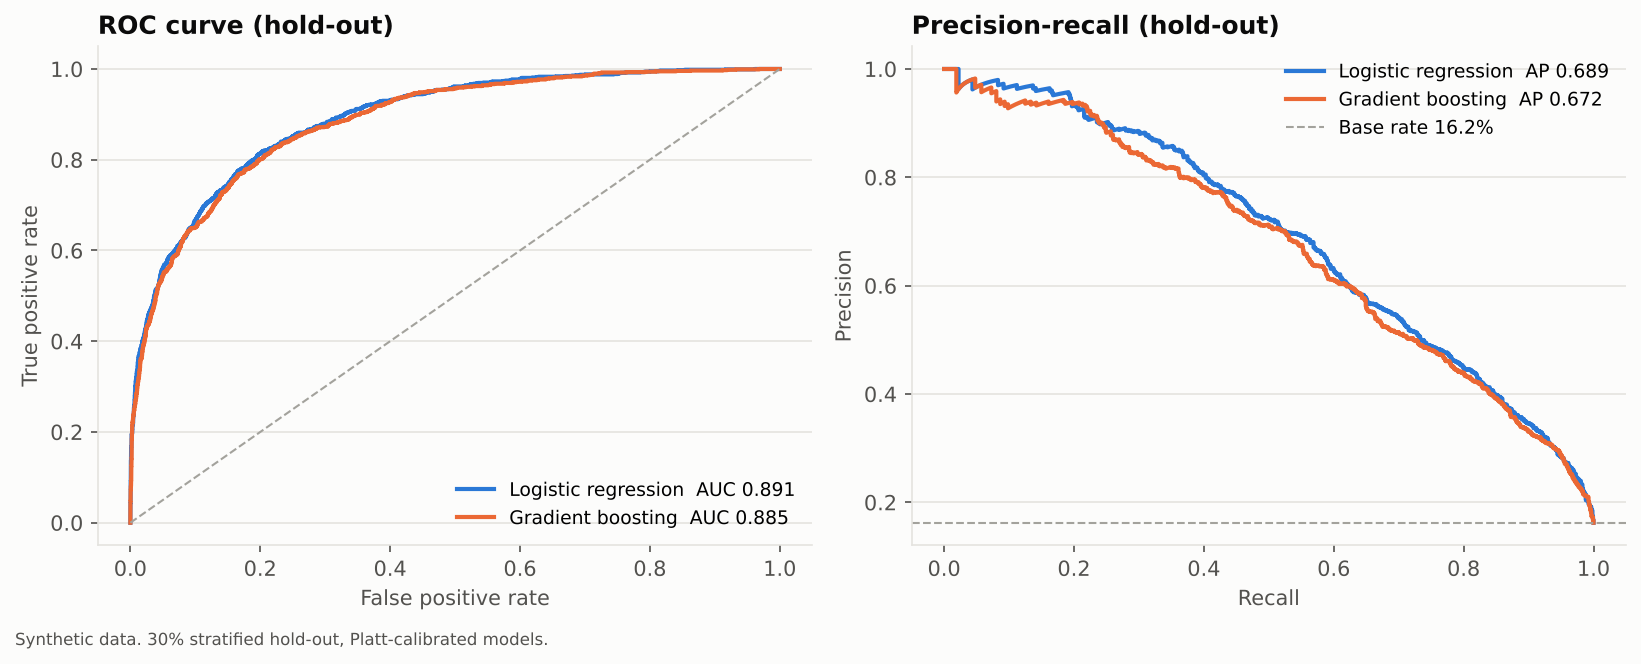

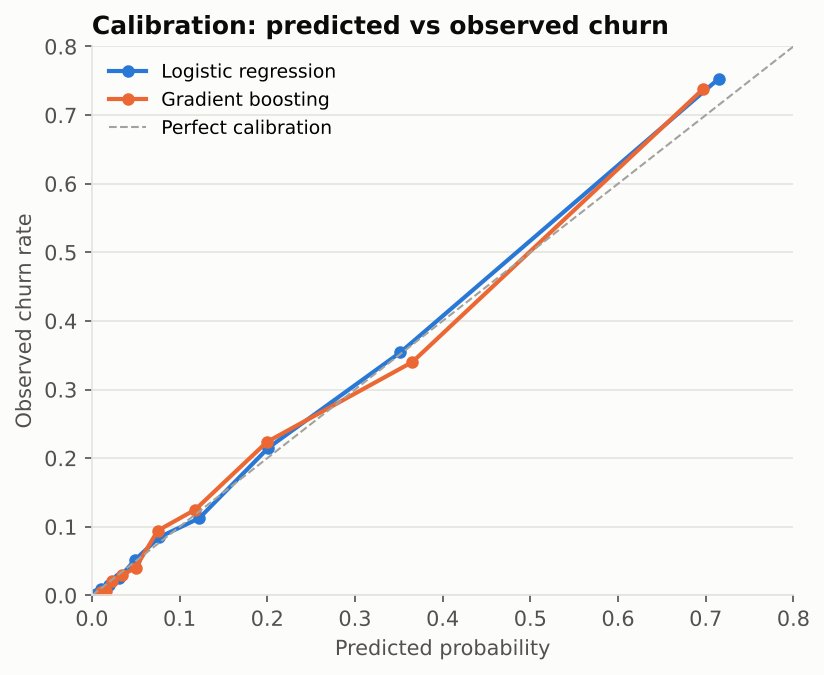

In [4]:
show('ml/01_churn_roc_pr.png'); show('ml/02_churn_calibration.png', 500)

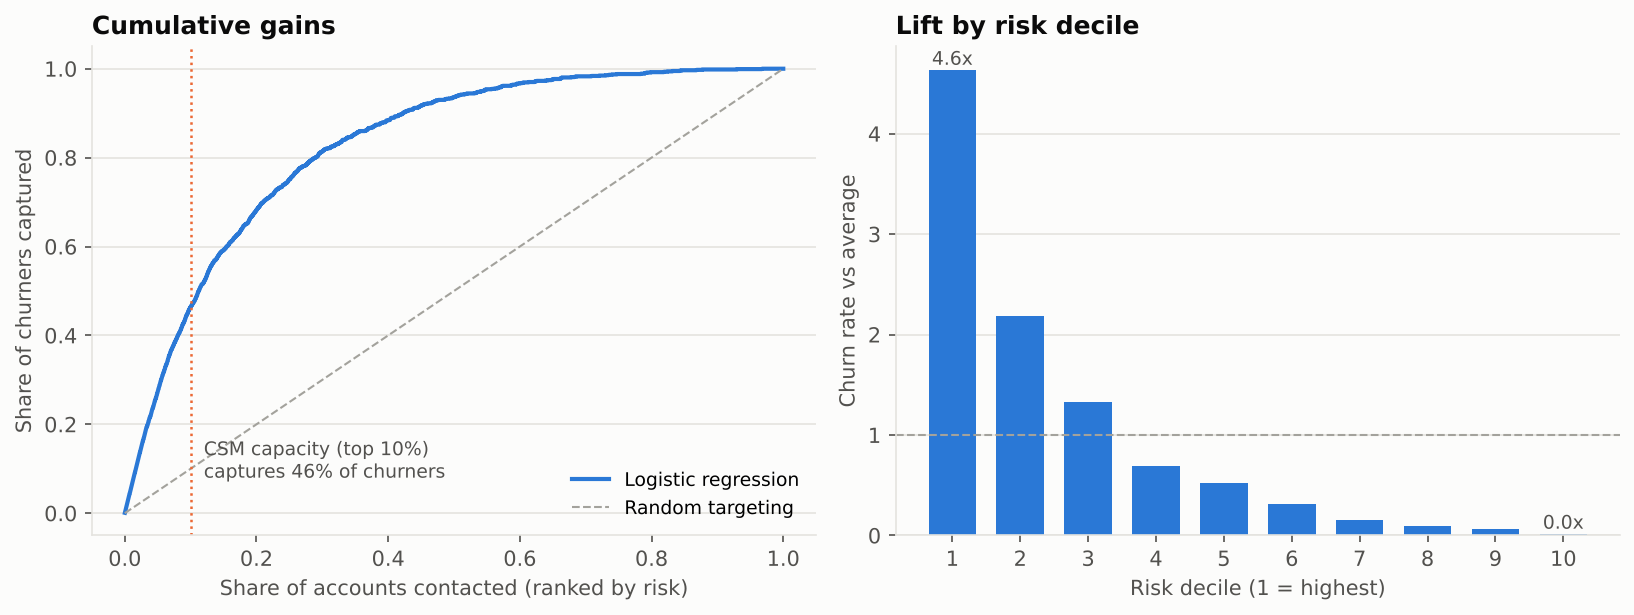

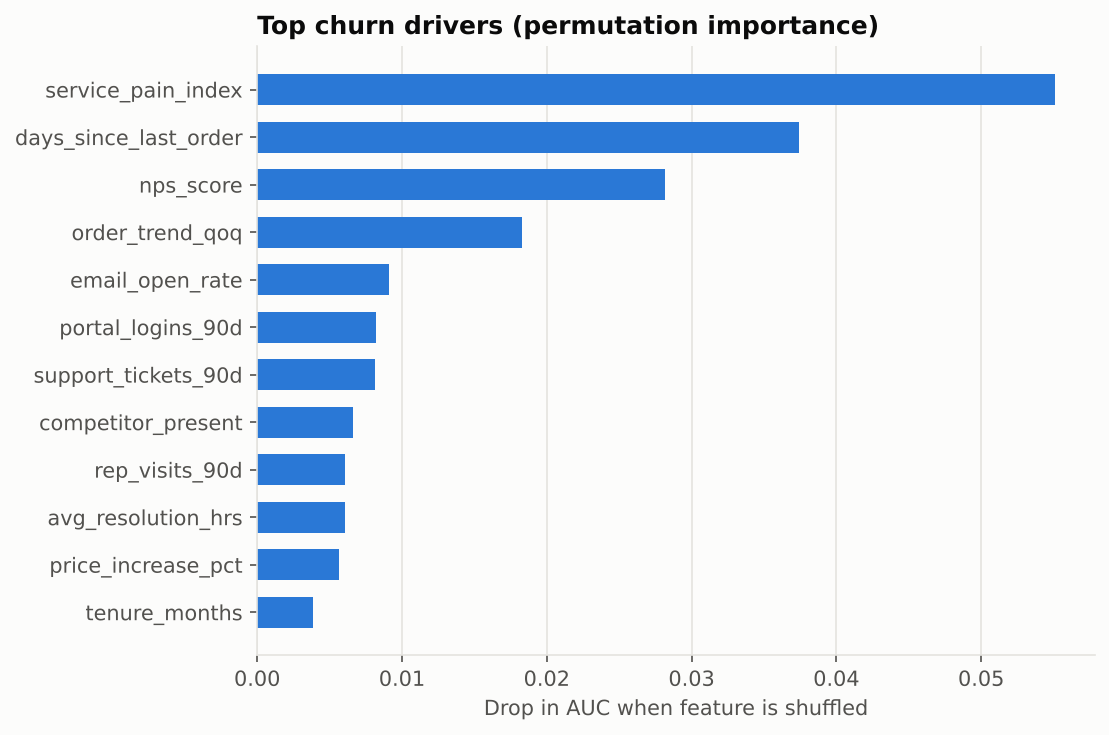

In [5]:
show('ml/03_churn_gains_lift.png'); show('ml/04_churn_feature_importance.png', 700)

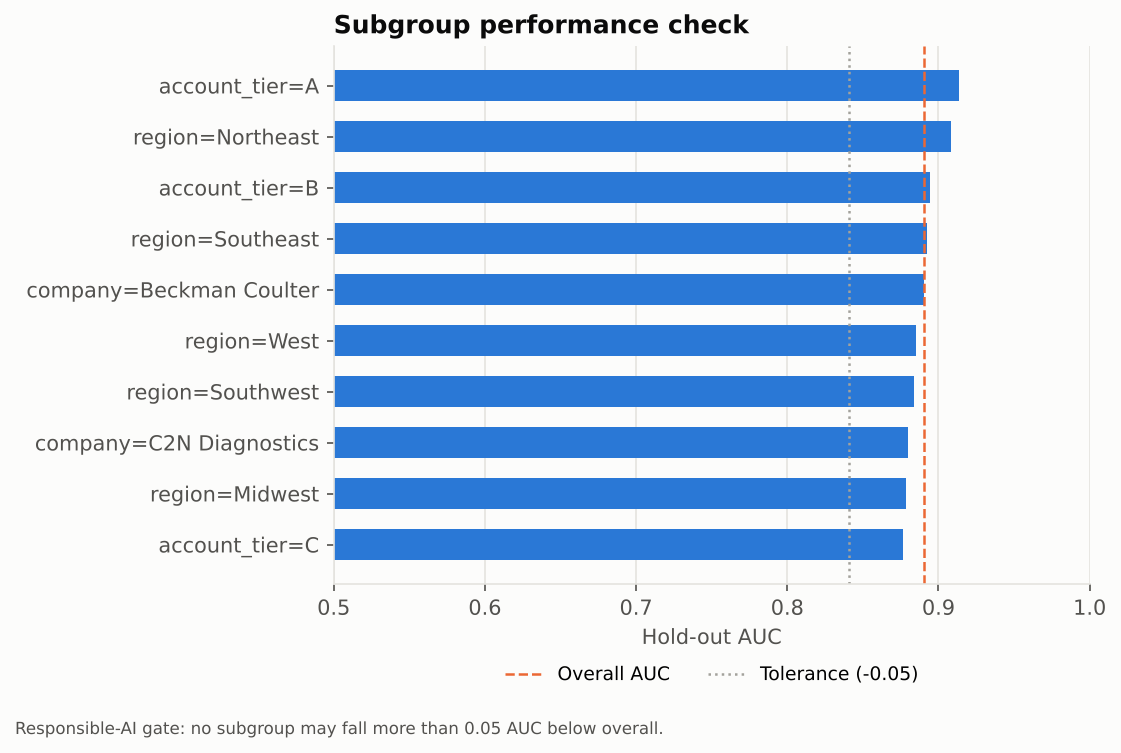

In [6]:
show('ml/05_churn_subgroup_auc.png', 700)

**Field-ready output**: a ranked worklist with plain-language reason codes, pushed to CRM for Customer Success.

In [7]:
pd.read_csv(ROOT / 'data/processed/churn_worklist_top250.csv').head(10)

,customer_id,company,customer_type,region,account_tier,churn_risk,top_reasons
0,CUST-012085,C2N Diagnostics,Neurology Practice,Midwest,B,0.9998,days_since_last_order (26%); service_pain_inde...
1,CUST-004202,Beckman Coulter,Physician Office Lab,West,C,0.9997,service_pain_index (35%); support_tickets_90d ...
2,CUST-013722,C2N Diagnostics,Memory Clinic,Midwest,A,0.9989,days_since_last_order (62%); competitor_presen...
3,CUST-015471,Beckman Coulter,Reference Lab,Midwest,C,0.9988,days_since_last_order (36%); service_pain_inde...
4,CUST-003335,Beckman Coulter,Reference Lab,Northeast,A,0.9987,support_tickets_90d (43%); service_pain_index ...
5,CUST-008142,Beckman Coulter,Hospital Lab,West,B,0.9981,service_pain_index (34%); support_tickets_90d ...
6,CUST-007609,C2N Diagnostics,Memory Clinic,Midwest,C,0.9975,service_pain_index (24%); support_tickets_90d ...
7,CUST-005701,Beckman Coulter,Hospital Lab,Midwest,A,0.9973,support_tickets_90d (28%); service_pain_index ...
8,CUST-000338,Beckman Coulter,IDN Core Lab,Southeast,A,0.9965,service_pain_index (33%); support_tickets_90d ...
9,CUST-004906,C2N Diagnostics,Neurology Practice,Midwest,C,0.9953,avg_resolution_hrs (41%); order_trend_qoq (19%...


## 2. Next-Best-Action uplift model (T-learner)
Trained on a historical 50/50 randomized outreach so the treatment effect is identifiable.

In [8]:
from cx_suite.ml import uplift_model
upl = uplift_model.run(df)
pd.DataFrame(upl['deciles']).round(3)

[uplift] qini=0.55 corr(true)=0.59 top-decile obs uplift=0.165 bottom=-0.007


,decile,observed_uplift,predicted_uplift,true_uplift
0,1,0.165,0.243,0.126
1,2,0.084,0.142,0.090
2,3,0.063,0.095,0.067
3,4,0.046,0.064,0.050
4,5,0.030,0.040,0.033
5,6,0.014,0.020,0.022
6,7,0.034,0.002,0.012
7,8,-0.001,-0.017,0.005
8,9,0.010,-0.043,0.005
9,10,-0.007,-0.111,-0.001


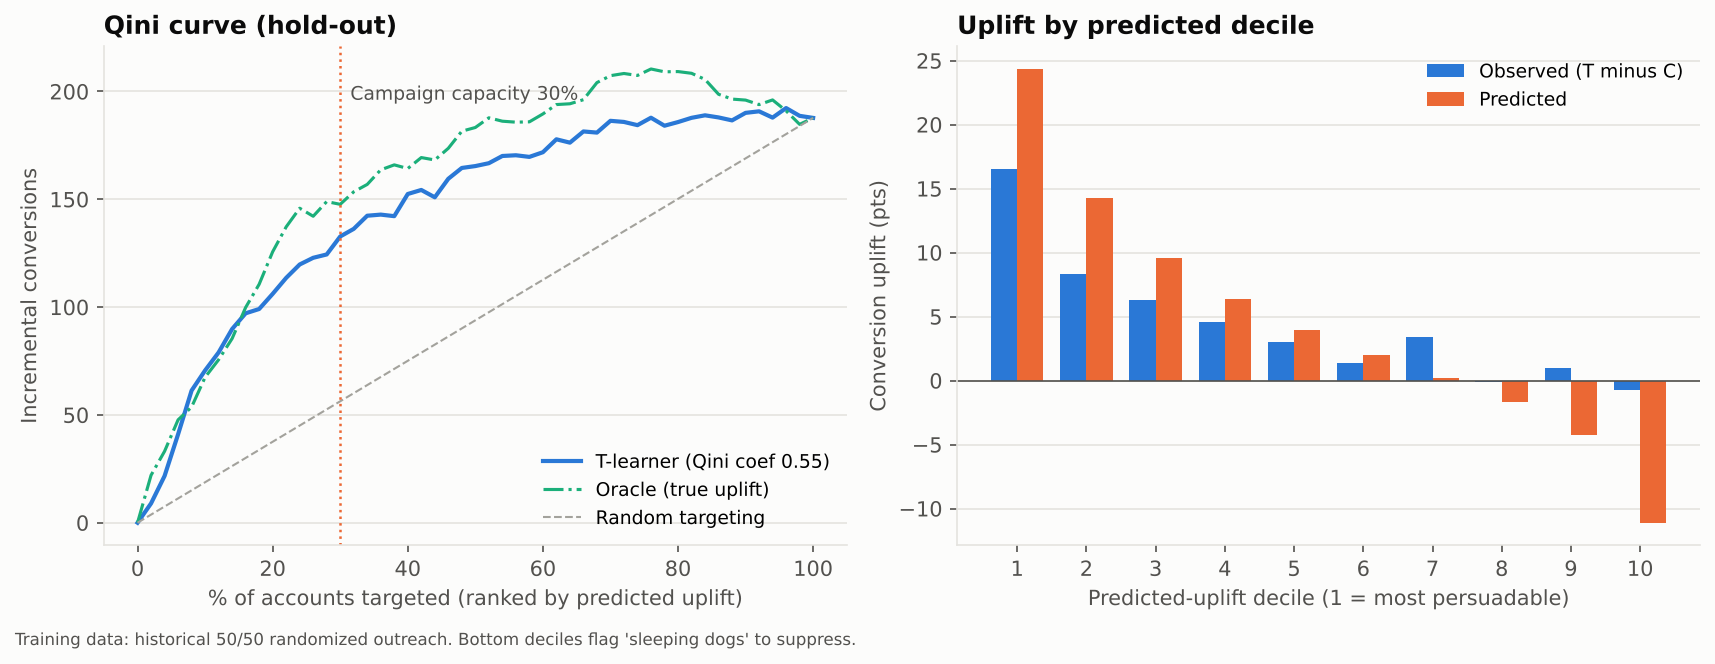

In [9]:
show('ml/06_nba_uplift_qini_deciles.png')

## 3. MVP pilot: A/B test design and readout
Pre-registration lives in `configs/pilot_preregistration.yaml`.

In [10]:
from cx_suite.ml import pilot_design
pilot = pilot_design.run()
{k: pilot[k] for k in ['power_analysis','abs_lift_pts','ci95_pts','relative_lift','p_value','guardrail_unsub_diff_pts','decision']}

[pilot] A=13.421% B=16.173% lift=2.75pts p=2.1e-08 -> SHIP / scale to Wave 2


{'power_analysis': {'baseline_rate': 0.13420523138833,
  'n_per_arm_for_1pt_mde': 18805,
  'n_per_arm_for_1_5pt_mde': 8481,
  'n_per_arm_for_2pt_mde': 4838},
 'abs_lift_pts': 2.7524390878071596,
 'ci95_pts': [1.7691906271592173, 3.735687548455102],
 'relative_lift': 0.20509178810197276,
 'p_value': 2.1261615734363313e-08,
 'guardrail_unsub_diff_pts': 0.14632526770963755,
 'decision': 'SHIP / scale to Wave 2'}

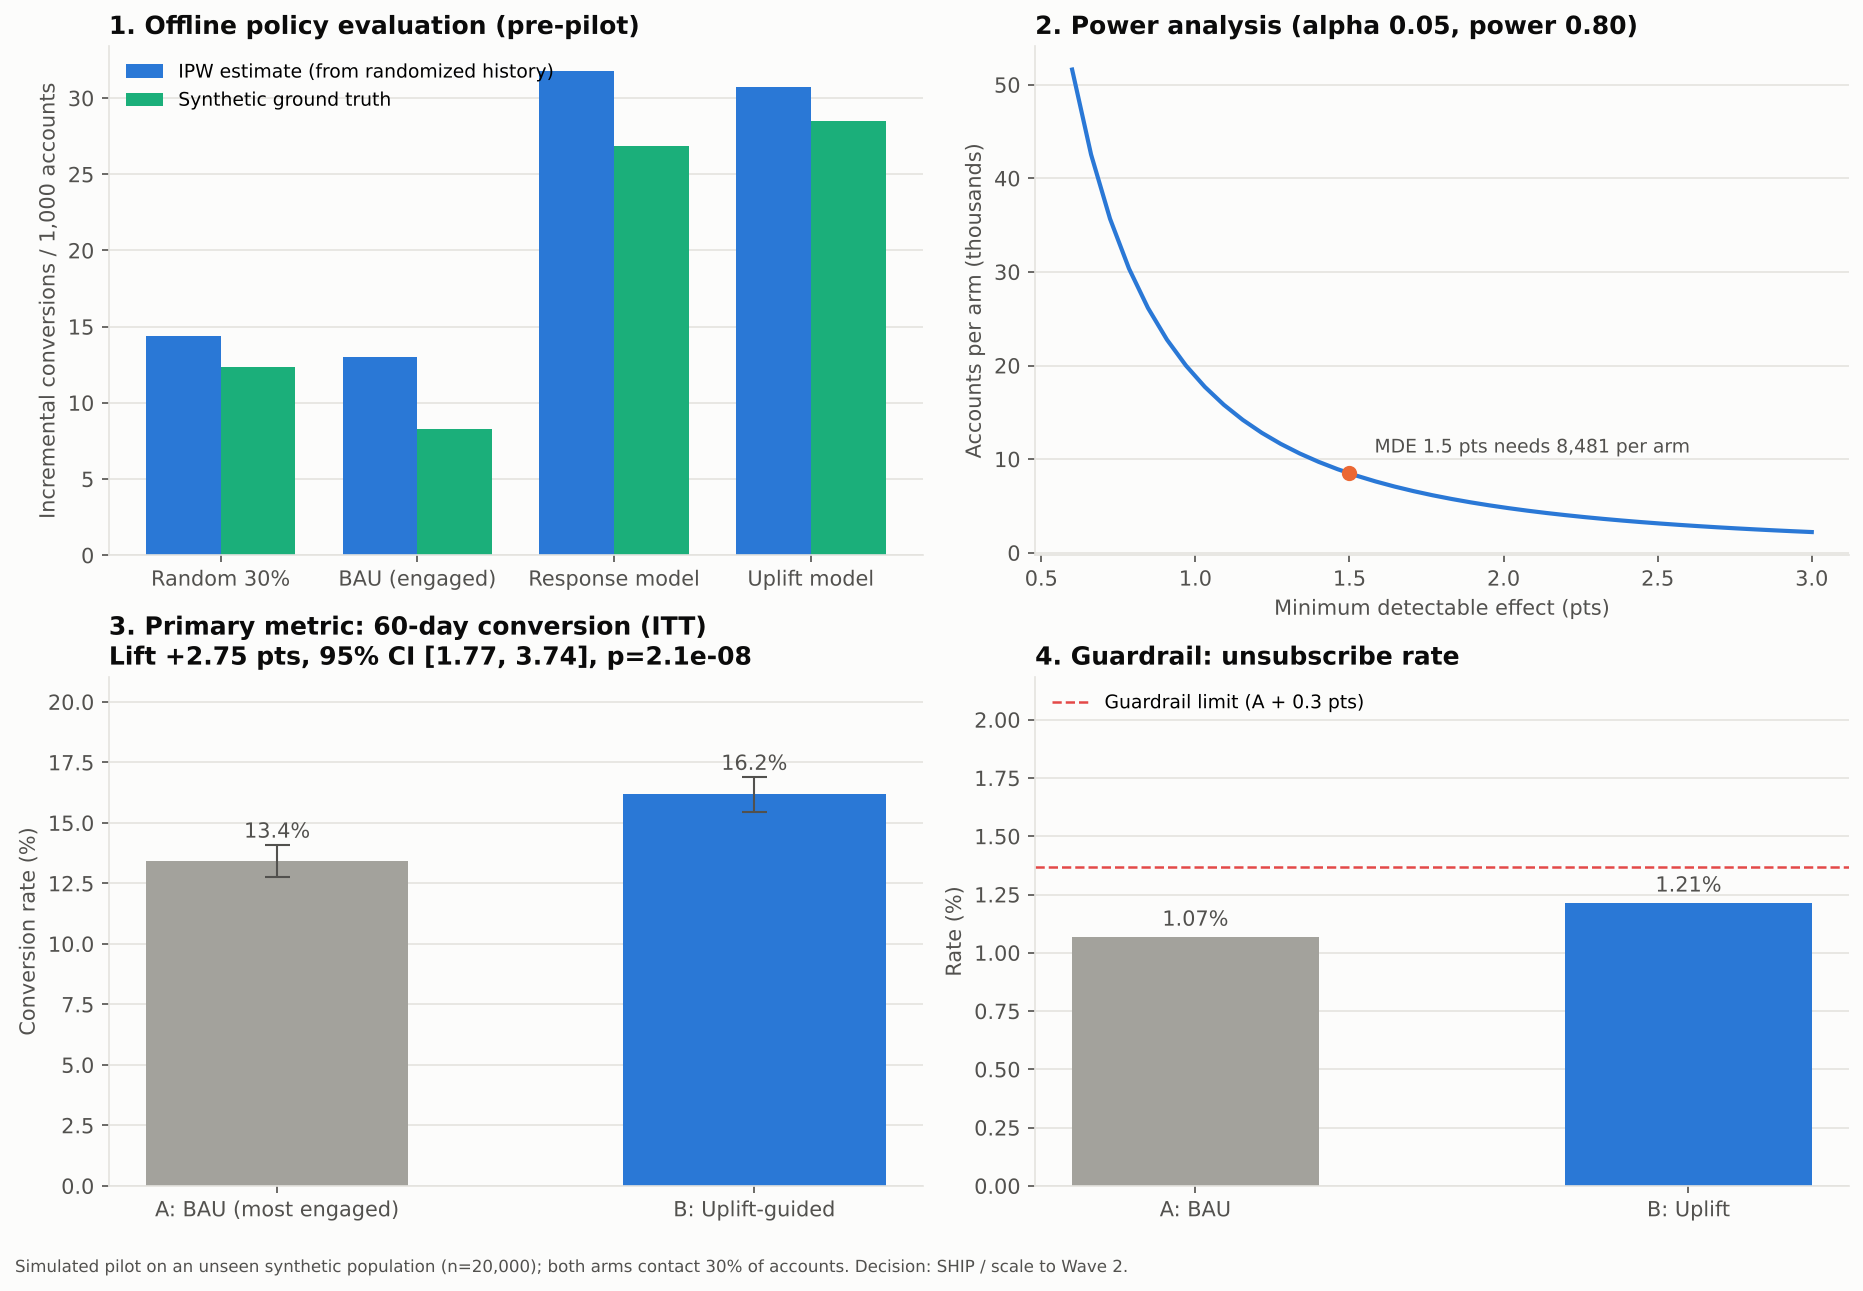

In [11]:
show('ml/07_pilot_power_and_readout.png')

## 4. Post-deployment monitoring

[drift] significant: ['email_open_rate']


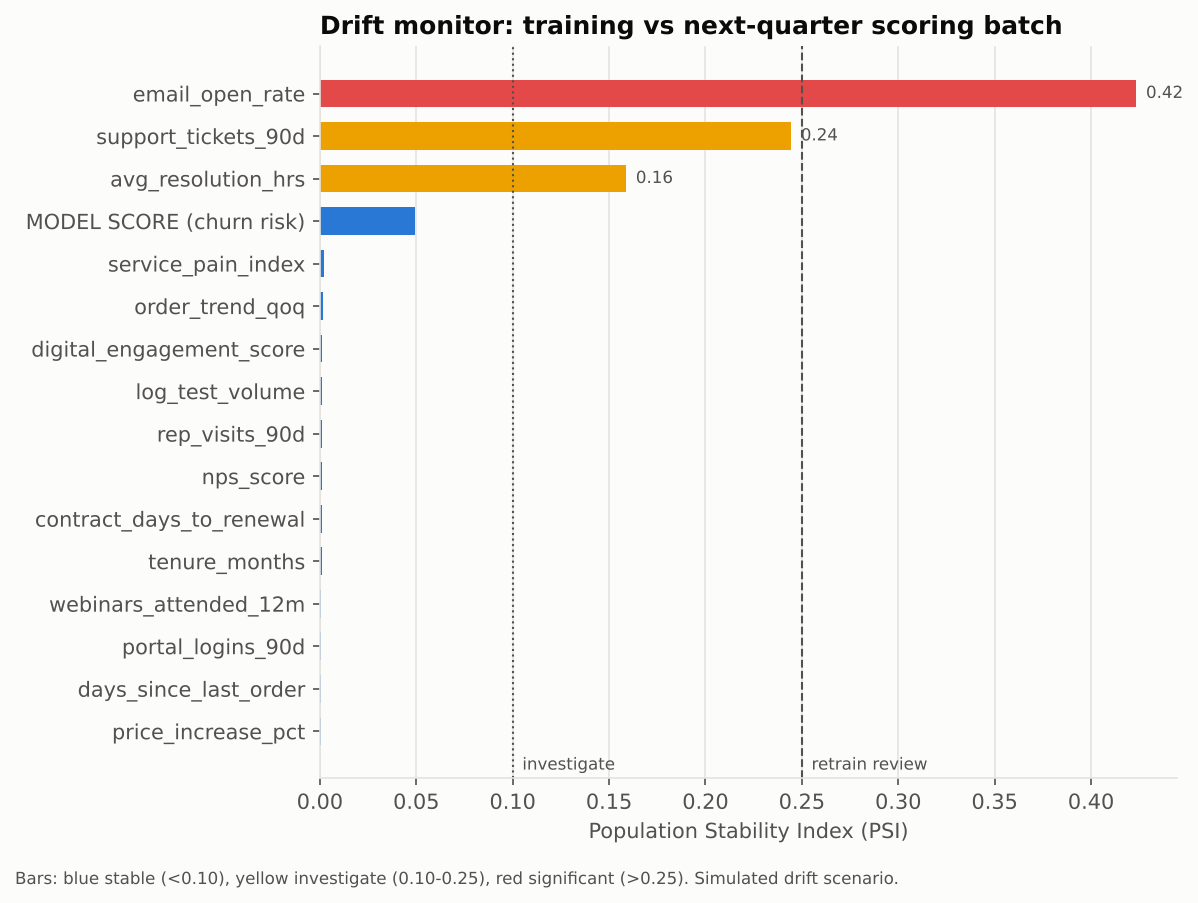

In [12]:
from cx_suite.ml import monitoring
drift = monitoring.run()
show('ml/08_drift_monitor_psi.png', 700)